In [1]:
"""
Data cleaning + EDA del dataset de productos de Amazon India (amazon.csv).
 
Estructura:
  PARTE 1. Carga y diagnostico inicial
  PARTE 2. Limpieza (cada paso explica el por que)
  PARTE 3. EDA (estadistica descriptiva, categorias, relaciones y graficos)
"""
import re
from pathlib import Path
 
#import matplotlib
#matplotlib.use("Agg")  # backend sin pantalla: impide que los gráficos aparezcan debajo de la celda
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
 
RUTA = Path("amazon.csv")
SALIDA = Path(".")    #Para que todas las salidas se guarden en la carpeta actual
FIG = SALIDA / "figuras"
FIG.mkdir(parents=True, exist_ok=True)
 
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 60)
 
 
def titulo(texto):
    print("\n" + "=" * 70 + f"\n{texto}\n" + "=" * 70)
 

In [2]:
# ======================================================================
# PARTE 1. CARGA Y DIAGNOSTICO INICIAL
# ======================================================================
titulo("1. DIAGNOSTICO INICIAL")
 
df_raw = pd.read_csv(RUTA)
print(f"Forma original: {df_raw.shape[0]} filas x {df_raw.shape[1]} columnas")
print("\nNulos por columna (solo las que tienen):")
print(df_raw.isna().sum()[lambda s: s > 0])
print(f"\nFilas totalmente duplicadas: {df_raw.duplicated().sum()}")
print(f"product_id repetidos: {df_raw.product_id.duplicated().sum()} "
      f"({df_raw.product_id.nunique()} productos unicos)")
 


1. DIAGNOSTICO INICIAL
Forma original: 1465 filas x 16 columnas

Nulos por columna (solo las que tienen):
rating_count    2
dtype: int64

Filas totalmente duplicadas: 0
product_id repetidos: 114 (1351 productos unicos)


In [4]:
df_raw.head()

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Charging and ...,Computers&Accessories|Accessories&Peripherals|Cables&Acc...,₹399,"₹1,099",64%,4.2,"24,269","High Compatibility : Compatible With iPhone 12, 11, X/Xs...","AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBBSNLYT3ONIL...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jaspreet singh...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1KD19VHEDV0O...","Satisfied,Charging is really fast,Value for money,Produc...","Looks durable Charging is fine tooNo complains,Charging ...",https://m.media-amazon.com/images/W/WEBP_402378-T1/image...,https://www.amazon.in/Wayona-Braided-WN3LG1-Syncing-Char...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5m Braided ...,Computers&Accessories|Accessories&Peripherals|Cables&Acc...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be it an and...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBXNGXZJT525A...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Placeholder,Bh...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RYGGS0M09S3K...","A Good Braided Cable for Your Type C Device,Good quality...",I ordered this cable to connect my phone to Android Auto...,https://m.media-amazon.com/images/W/WEBP_402378-T2/image...,https://www.amazon.in/Ambrane-Unbreakable-Charging-Braid...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync USB Cable C...,Computers&Accessories|Accessories&Peripherals|Cables&Acc...,₹199,"₹1,899",90%,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safety proctect...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQLWQOWZ4N3O...","Kunal,Himanshu,viswanath,sai niharka,saqib malik,Aashiq,...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R25X4TBMPY91...","Good speed for earlier versions,Good Product,Working goo...","Not quite durable and sturdy,https://m.media-amazon.com/...",https://m.media-amazon.com/images/W/WEBP_402378-T1/image...,https://www.amazon.in/Sounce-iPhone-Charging-Compatible-...
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB Stress Resi...,Computers&Accessories|Accessories&Peripherals|Cables&Acc...,₹329,₹699,53%,4.2,"94,363",The boAt Deuce USB 300 2 in 1 cable is compatible with s...,"AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5SGCUQBP7YSC...","Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh chouhan,Ra...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1CLH2ULIVG5...","Good product,Good one,Nice,Really nice product,Very firs...","Good product,long wire,Charges good,Nice,I bought this c...",https://m.media-amazon.com/images/I/41V5FtEWPkL._SX300_S...,https://www.amazon.in/Deuce-300-Resistant-Tangle-Free-Tr...
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 Pin USB Cab...,Computers&Accessories|Accessories&Peripherals|Cables&Acc...,₹154,₹399,61%,4.2,"16,905",[CHARGE & SYNC FUNCTION]- This cable comes with charging...,"AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZHM4QB2KPKFU...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK,Bhargav,D...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R3KK4GT934S...","As good as original,Decent,Good one for secondary use,Be...","Bought this instead of original apple, does the work for...",https://m.media-amazon.com/images/W/WEBP_402378-T2/image...,https://www.amazon.in/Portronics-Konnect-POR-1080-Chargi...


In [5]:
# PARTE 2. LIMPIEZA

titulo("2. LIMPIEZA")
df = df_raw.copy()  # trabajamos sobre una copia para conservar el original
registro = []       # bitacora de decisiones
 
 
# 2.1 Precios: de texto a numero 1099.0 

for col in ["discounted_price", "actual_price"]:
    df[col] = df[col].str.replace(r"[₹,]", "", regex=True).astype(float)
registro.append("Precios convertidos de '₹1,099' a float (quitando simbolo y comas).")
 
# 2.2 Porcentaje de descuento: "64%" a 64.0 
df["discount_percentage"] = df["discount_percentage"].str.rstrip("%").astype(float)
registro.append("discount_percentage convertido de '64%' a float.")
 
#2.3 Rating: hay un valor basura '|'
# errors="coerce" convierte lo que no sea numero en NaN en vez de fallar.
# NO imputamos: inventar un rating para ese producto sesgaria el analisis.
n_malos = pd.to_numeric(df["rating"], errors="coerce").isna().sum() - df["rating"].isna().sum()
df["rating"] = pd.to_numeric(df["rating"], errors="coerce")
registro.append(f"rating: {n_malos} valor no numerico ('|') convertido a NaN (no imputado para evitar sesgos).")
 
#2.4 rating_count: "1,07,687" (quitamos todas las comas) a 107687 

df["rating_count"] = pd.to_numeric(
    df["rating_count"].str.replace(",", "", regex=False), errors="coerce"
)
registro.append("rating_count convertido a numero (formato indio '1,07,687' a 107687). "
                f"{df['rating_count'].isna().sum()} nulos se dejan como NaN.")
 
#2.5 Duplicados por product_id 
"""El mismo producto aparece varias veces porque se capturo en distintas posiciones de busqueda 
Los datos son casi identicos; difieren por 1-2 unidades en rating_count y, en 3 productos, en el precio. 
Conservaremos la captura con MAYOR rating_count, porque ese contador solo crece con el tiempo."""

antes = len(df)
df = (
    df.sort_values("rating_count", ascending=False, na_position="last")
      .drop_duplicates(subset="product_id", keep="first")
      .sort_index()
)
registro.append(f"Duplicados por product_id: {antes - len(df)} filas eliminadas "
                f"(se conserva la de mayor rating_count). Quedan {len(df)} productos.")
 
#2.5b Texto: espacios sobrantes
df["product_name"] = df["product_name"].str.strip().str.replace(r"\s+", " ", regex=True)
 
 
#2.6 Categorias: de "A|B|C|D" a columnas jerarquicas
# La columna 'category' guarda toda la jerarquia en un solo texto. La
# separamos por '|' y damos formato legible a los nombres
# ("Computers&Accessories" a "Computers & Accessories").
def nombre_legible(s):
    s = s.replace("&", " & ").replace(",", ", ")
    s = re.sub(r"(?<=[a-z])(?=[A-Z])", " ", s)           # OfficeProducts a Office Products
    s = re.sub(r"(?<=[A-Z])(?=[A-Z][a-z])", " ", s)      # HDMICables a HDMI Cables
    return re.sub(r"\s+", " ", s).strip()
 
 
niveles = df["category"].str.split("|")
df["main_category"] = niveles.str[0].map(nombre_legible)
df["sub_category"] = niveles.str[1].map(nombre_legible)
df["leaf_category"] = niveles.str[-1].map(nombre_legible)
registro.append("category separada en main_category, sub_category y leaf_category.")
 
# 2.7 Variables derivadas 
df["discount_amount"] = df["actual_price"] - df["discounted_price"]
df["price_range"] = pd.cut(
    df["discounted_price"],
    bins=[0, 500, 1000, 5000, 20000, np.inf],
    labels=["<500", "500-1k", "1k-5k", "5k-20k", ">20k"],
)
registro.append("Nuevas columnas: discount_amount (rupias) y price_range (tramos de precio).")
 
# 2.8 Limpieza del link y columnas de reseñas
# El link trae parametros de tracking tras '/ref='; los quitamos.
df["product_link"] = df["product_link"].str.split("/ref=").str[0]
# user_id, user_name, review_id, review_title y review_content guardan ~8
# reseñas concatenadas con comas (y el texto de las reseñas tambien
# contiene comas), asi que no se pueden separar de forma confiable.
# Ademas user_id/user_name son datos personales. Se descartan, junto con
# img_link, que no aporta al analisis.
columnas_fuera = ["user_id", "user_name", "review_id", "review_title",
                  "review_content", "img_link"]
df = df.drop(columns=columnas_fuera)
registro.append(f"Columnas descartadas: {', '.join(columnas_fuera)}.")
 
#2.9 Validaciones de coherencia
titulo("2.9 VALIDACIONES")
desc_calc = (1 - df["discounted_price"] / df["actual_price"]) * 100
print("Descuento reportado vs recalculado (diferencia > 1 punto):",
      int(((desc_calc - df["discount_percentage"]).abs() > 1).sum()))
print("Precio con descuento > precio real:", int((df["discounted_price"] > df["actual_price"]).sum()))
print("Ratings fuera de [1, 5]:", int((~df["rating"].dropna().between(1, 5)).sum()))
print("Precios <= 0:", int((df["discounted_price"] <= 0).sum()))
 
titulo("BITACORA DE LIMPIEZA")
for i, paso in enumerate(registro, 1):
    print(f"{i}. {paso}")
 
orden = ["product_id", "product_name", "main_category", "sub_category", "leaf_category",
         "category", "discounted_price", "actual_price", "discount_amount",
         "discount_percentage", "price_range", "rating", "rating_count",
         "about_product", "product_link"]
df = df[orden].reset_index(drop=True)
df.to_csv(SALIDA / "amazon_limpio.csv", index=False, encoding="utf-8")
print(f"\nDataset limpio: {df.shape[0]} filas x {df.shape[1]} columnas -> amazon_limpio.csv")
df.head()


2. LIMPIEZA

2.9 VALIDACIONES
Descuento reportado vs recalculado (diferencia > 1 punto): 0
Precio con descuento > precio real: 0
Ratings fuera de [1, 5]: 0
Precios <= 0: 0

BITACORA DE LIMPIEZA
1. Precios convertidos de '₹1,099' a float (quitando simbolo y comas).
2. discount_percentage convertido de '64%' a float.
3. rating: 1 valor no numerico ('|') convertido a NaN (no imputado para evitar sesgos).
4. rating_count convertido a numero (formato indio '1,07,687' a 107687). 2 nulos se dejan como NaN.
5. Duplicados por product_id: 114 filas eliminadas (se conserva la de mayor rating_count). Quedan 1351 productos.
6. category separada en main_category, sub_category y leaf_category.
7. Nuevas columnas: discount_amount (rupias) y price_range (tramos de precio).
8. Columnas descartadas: user_id, user_name, review_id, review_title, review_content, img_link.

Dataset limpio: 1351 filas x 15 columnas -> amazon_limpio.csv


,product_id,product_name,main_category,sub_category,leaf_category,category,discounted_price,actual_price,discount_amount,discount_percentage,price_range,rating,rating_count,about_product,product_link
0,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5m Braided ...,Computers & Accessories,Accessories & Peripherals,USB Cables,Computers&Accessories|Accessories&Peripherals|Cables&Acc...,199.0,349.0,150.0,43.0,<500,4.0,43994.0,"Compatible with all Type C enabled devices, be it an and...",https://www.amazon.in/Ambrane-Unbreakable-Charging-Braid...
1,B08Y1TFSP6,pTron Solero TB301 3A Type-C Data and Fast Charging Cabl...,Computers & Accessories,Accessories & Peripherals,USB Cables,Computers&Accessories|Accessories&Peripherals|Cables&Acc...,149.0,1000.0,851.0,85.0,<500,3.9,24871.0,Fast Charging & Data Sync: Solero TB301 Type-C cable sup...,https://www.amazon.in/Solero-TB301-Charging-480Mbps-1-5-...
2,B008IFXQFU,"TP-Link USB WiFi Adapter for PC(TL-WN725N), N150 Wireles...",Computers & Accessories,Networking Devices,Wireless USB Adapters,Computers&Accessories|NetworkingDevices|NetworkAdapters|...,499.0,999.0,500.0,50.0,<500,4.2,179691.0,USB WiFi Adapter —— Speedy wireless transmission at up t...,https://www.amazon.in/TP-Link-TL-WN725N-150Mbps-Wireless...
3,B08CF3D7QR,Portronics Konnect L POR-1081 Fast Charging 3A Type-C Ca...,Computers & Accessories,Accessories & Peripherals,USB Cables,Computers&Accessories|Accessories&Peripherals|Cables&Acc...,154.0,339.0,185.0,55.0,<500,4.3,13391.0,[CHARGE & SYNC FUNCTION]- This cable comes with charging...,https://www.amazon.in/Portronics-POR-1081-Charging-1-2Me...
4,B07KSMBL2H,"AmazonBasics Flexible Premium HDMI Cable (Black, 4K@60Hz...",Electronics,"Home Theater, TV & Video",HDMI Cables,"Electronics|HomeTheater,TV&Video|Accessories|Cables|HDMI...",219.0,700.0,481.0,69.0,<500,4.4,426973.0,"Flexible, lightweight HDMI cable for connecting media de...",https://www.amazon.in/AmazonBasics-Flexible-HDMI-Cable-3...


In [6]:
# PARTE 3. EDA

titulo("3.1 ESTADISTICA DESCRIPTIVA")
num = ["discounted_price", "actual_price", "discount_percentage", "rating", "rating_count"]
print(df[num].describe().round(2))
print("\nSkew (asimetria) - valores >1 indican cola larga a la derecha:")
print(df[num].skew().round(2))
 
titulo("3.2 OUTLIERS (regla IQR 1.5)")
for col in ["discounted_price", "rating_count"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    lim = q3 + 1.5 * (q3 - q1)
    n = (df[col] > lim).sum()
    print(f"{col}: limite superior {lim:,.0f} -> {n} productos por encima ({n / len(df):.1%})")
 
titulo("3.3 CATEGORIAS")
print(df["main_category"].value_counts())
print("\nTop 10 subcategorias por cantidad de productos:")
print(df["sub_category"].value_counts().head(10))
 
principales = df["main_category"].value_counts()[lambda s: s >= 10].index
resumen_cat = (
    df[df["main_category"].isin(principales)]
    .groupby("main_category")
    .agg(productos=("product_id", "count"),
         precio_mediano=("discounted_price", "median"),
         descuento_mediano=("discount_percentage", "median"),
         rating_medio=("rating", "mean"),
         rating_count_mediano=("rating_count", "median"))
    .round(2)
)
print("\nResumen por categoria principal (categorias con >= 10 productos):")
print(resumen_cat)
 
# Subcategorias con al menos 15 productos para que la mediana sea estable
sub = (
    df.groupby("sub_category")
      .agg(productos=("product_id", "count"),
           descuento_mediano=("discount_percentage", "median"),
           rating_medio=("rating", "mean"),
           precio_mediano=("discounted_price", "median"))
      .query("productos >= 15")
      .round(2)
)
print("\nSubcategorias con mayor descuento mediano (>= 15 productos):")
print(sub.sort_values("descuento_mediano", ascending=False).head(8))
print("\nSubcategorias con menor descuento mediano (>= 15 productos):")
print(sub.sort_values("descuento_mediano").head(5))
 
titulo("3.4 TOP PRODUCTOS")
print("Top 10 por numero de ratings:")
print(df.nlargest(10, "rating_count")[["product_name", "main_category", "discounted_price",
                                         "rating", "rating_count"]].assign(
    product_name=lambda d: d.product_name.str[:55]))
print("\nTop 5 por mayor descuento % (con >= 100 ratings):")
print(df[df.rating_count >= 100].nlargest(5, "discount_percentage")[
    ["product_name", "discounted_price", "actual_price", "discount_percentage", "rating"]
].assign(product_name=lambda d: d.product_name.str[:55]))
print("\nProductos con rating >= 4.5 y >= 1000 ratings:",
      int(((df.rating >= 4.5) & (df.rating_count >= 1000)).sum()))
print("Productos sin descuento (0%):", int((df.discount_percentage == 0).sum()))
 
titulo("3.4b VARIANTES: rating_count COMPARTIDO ENTRE product_id DISTINTOS")
# Amazon agrupa variantes (color, tamano) bajo un producto "padre" y muestra
# el conteo de ratings del grupo. Si varios product_id comparten EXACTAMENTE
# el mismo rating_count, ese numero no es independiente por fila.
# Es una medida conservadora: la captura en momentos distintos dejo
# diferencias de 1-4 unidades entre variantes, que esta prueba no detecta,
# y en conteos bajos puede haber coincidencias por azar.
tam = df.groupby("rating_count")["product_id"].transform("count")
print("Productos que comparten rating_count exacto con otro product_id:",
      int((tam > 1).sum()), f"({(tam > 1).mean():.1%})")
print("Valores de rating_count compartidos:", int(df.groupby("rating_count").size().gt(1).sum()))
 
titulo("3.5 CORRELACIONES (Spearman)")
# Spearman y no Pearson: precio y rating_count tienen colas muy largas y
# Spearman mide relacion monotona por rangos, sin que los extremos dominen.
tmp = df[["rating", "rating_count", "discounted_price", "discount_percentage"]].dropna()
corr = tmp.corr(method="spearman").round(2)
print(corr)
 
titulo("3.6 PRECIO Y RATING POR TRAMO DE PRECIO")
print(df.groupby("price_range", observed=True).agg(
    productos=("product_id", "count"),
    rating_medio=("rating", "mean"),
    descuento_mediano=("discount_percentage", "median"),
    rating_count_mediano=("rating_count", "median")).round(2))
 


3.1 ESTADISTICA DESCRIPTIVA
       discounted_price  actual_price  discount_percentage   rating  rating_count
count           1351.00       1351.00              1351.00  1350.00       1349.00
mean            3304.73       5690.51                46.68     4.09      17644.52
std             7173.99      11218.92                21.62     0.30      42145.66
min               39.00         39.00                 0.00     2.00          2.00
25%              349.00        899.00                31.00     3.90       1106.00
50%              899.00       1790.00                49.00     4.10       4740.00
75%             2174.00       4575.00                62.00     4.30      16020.00
max            77990.00     139900.00                94.00     5.00     426973.00

Skew (asimetria) - valores >1 indican cola larga a la derecha:
discounted_price       4.30
actual_price           4.43
discount_percentage   -0.24
rating                -1.23
rating_count           5.69
dtype: float64

3.2 OUTLIERS 

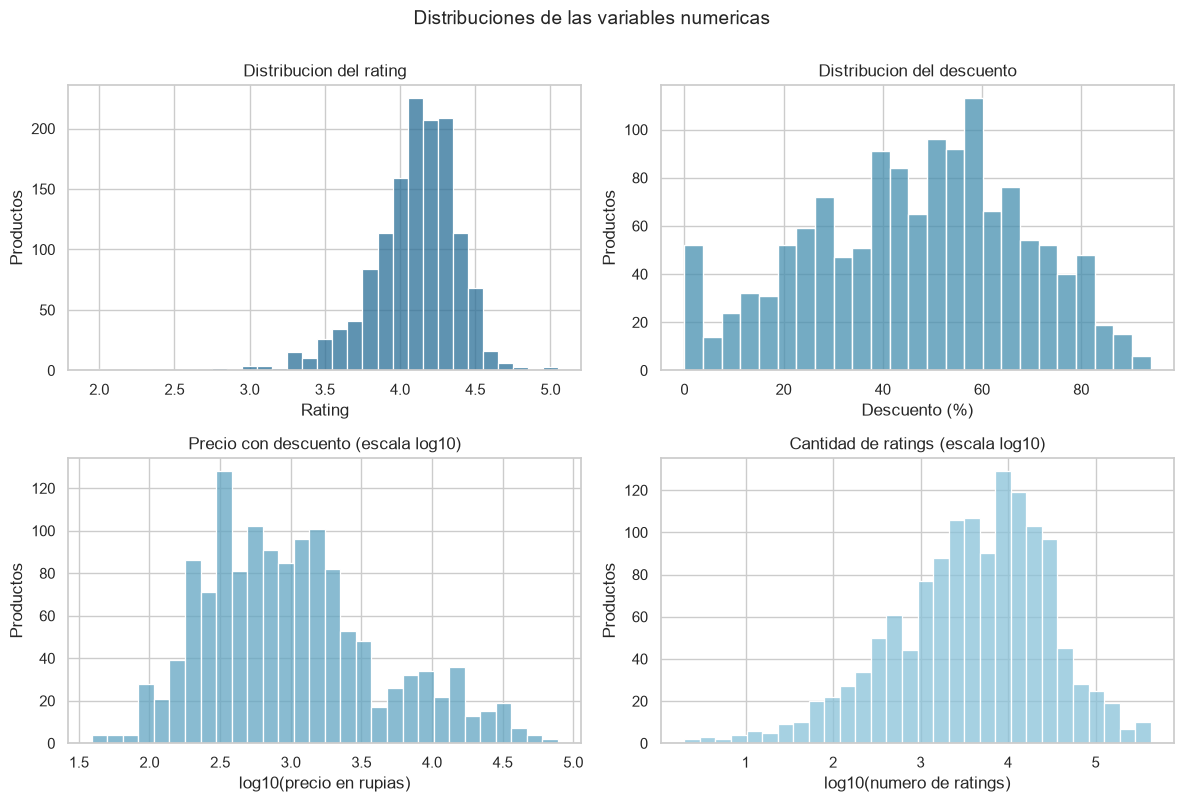

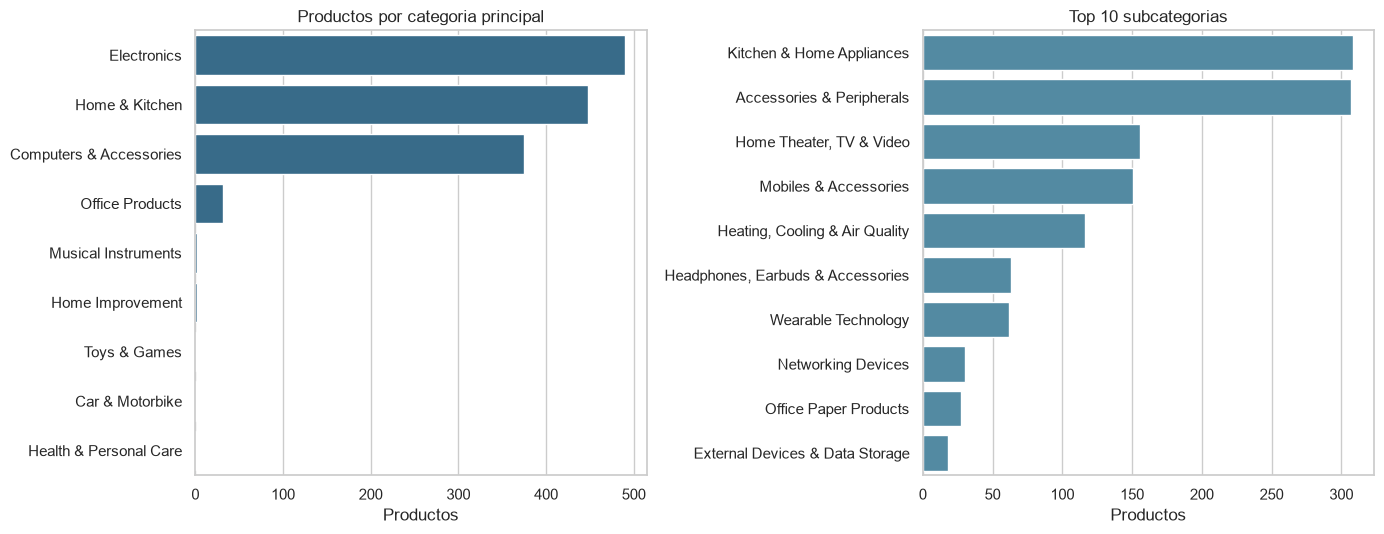

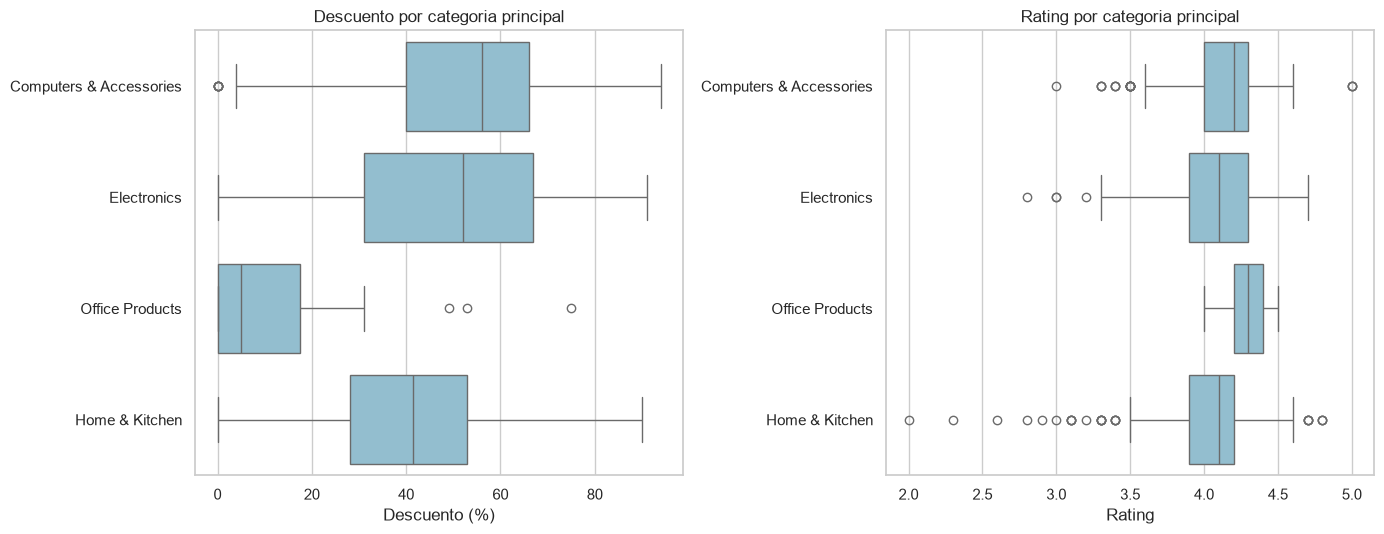

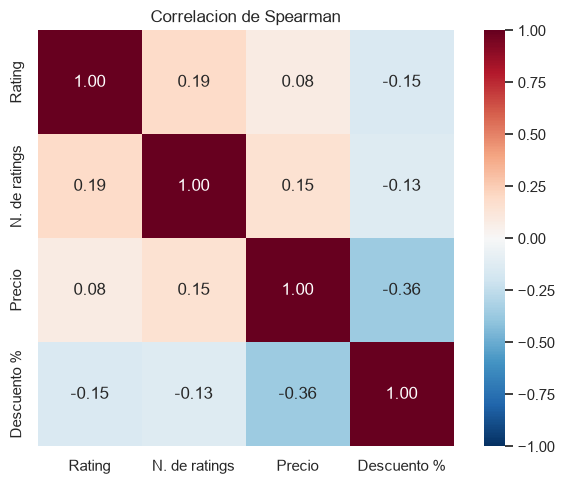

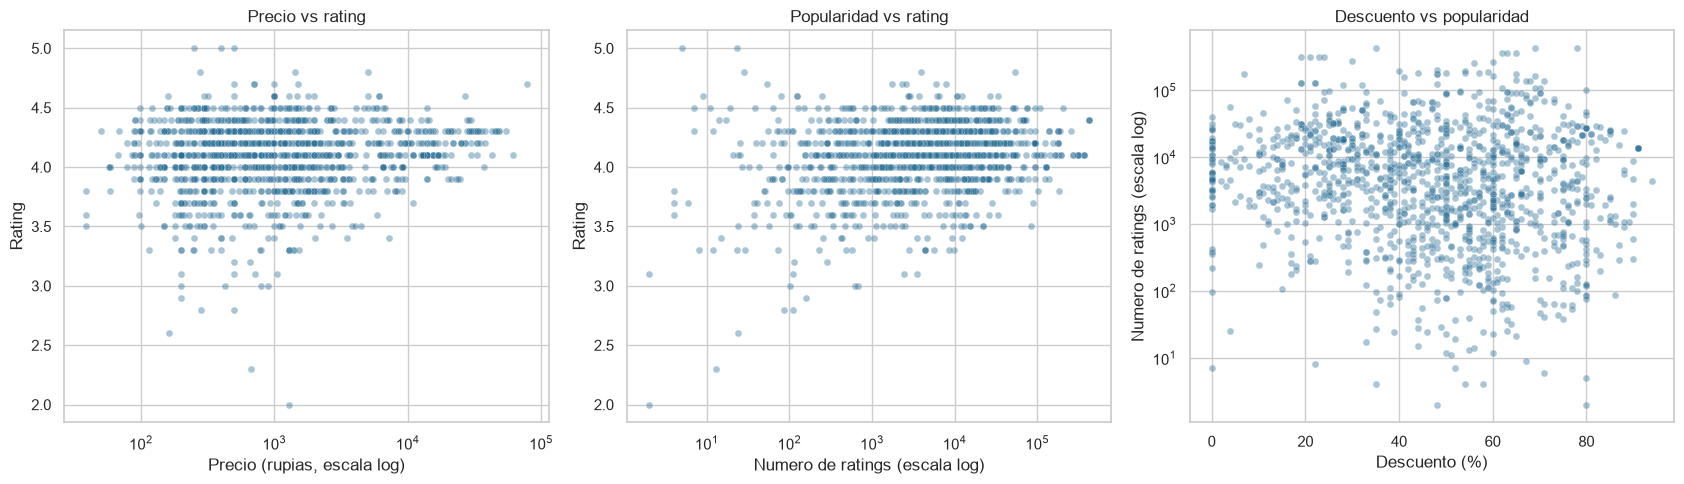

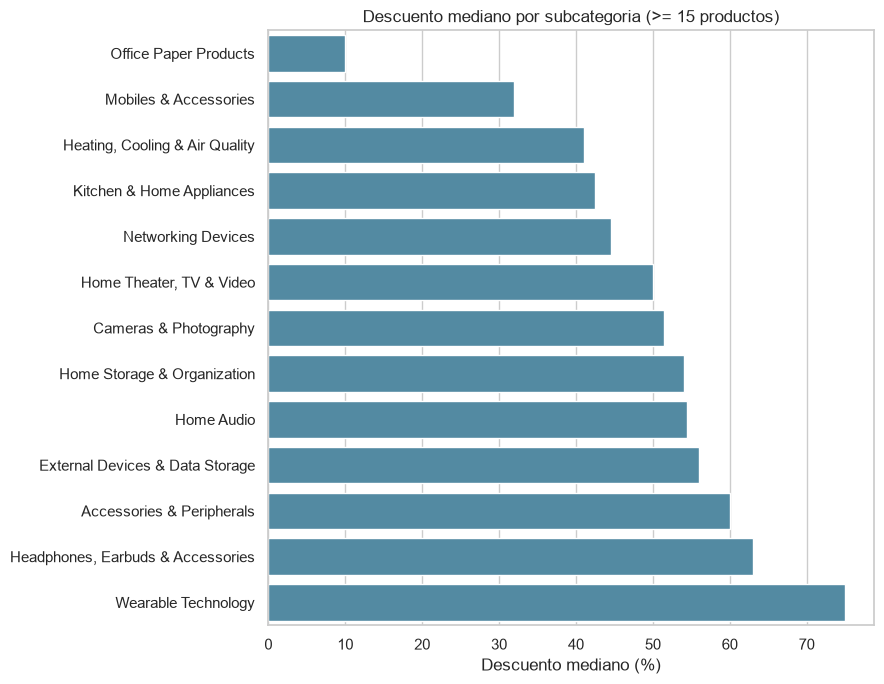


Figuras guardadas en: figuras


In [7]:
# GRAFICOS

# Fig 1: distribuciones. Precio y rating_count se grafican en log10 porque
# tienen cola muy larga y en escala lineal casi todo se aplasta a la izquierda.
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
# El rating toma valores en pasos de 0.1: usamos un bin por valor, centrado en el
# (de lo contrario las barras se desalinean y la forma se distorsiona).
sns.histplot(df["rating"].dropna(), bins=np.arange(1.95, 5.1, 0.1), ax=ax[0, 0],
             color="#2a6f97")
ax[0, 0].set(title="Distribucion del rating", xlabel="Rating", ylabel="Productos")
sns.histplot(df["discount_percentage"], bins=25, ax=ax[0, 1], color="#468faf")
ax[0, 1].set(title="Distribucion del descuento", xlabel="Descuento (%)", ylabel="Productos")
sns.histplot(np.log10(df["discounted_price"]), bins=30, ax=ax[1, 0], color="#61a5c2")
ax[1, 0].set(title="Precio con descuento (escala log10)", xlabel="log10(precio en rupias)",
             ylabel="Productos")
sns.histplot(np.log10(df["rating_count"].dropna()), bins=30, ax=ax[1, 1], color="#89c2d9")
ax[1, 1].set(title="Cantidad de ratings (escala log10)", xlabel="log10(numero de ratings)",
             ylabel="Productos")
fig.suptitle("Distribuciones de las variables numericas", fontsize=14, y=1.00)
fig.tight_layout()
fig.savefig(FIG / "fig1_distribuciones.png", dpi=130, bbox_inches="tight")
plt.show()
 
# Fig 2: categorias
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
conteo_main = df["main_category"].value_counts()
sns.barplot(x=conteo_main.values, y=conteo_main.index, ax=ax[0], color="#2a6f97")
ax[0].set(title="Productos por categoria principal", xlabel="Productos", ylabel="")
conteo_sub = df["sub_category"].value_counts().head(10)
sns.barplot(x=conteo_sub.values, y=conteo_sub.index, ax=ax[1], color="#468faf")
ax[1].set(title="Top 10 subcategorias", xlabel="Productos", ylabel="")
fig.tight_layout()
fig.savefig(FIG / "fig2_categorias.png", dpi=130, bbox_inches="tight")
plt.show()
 
# Fig 3: descuento y rating por categoria principal (solo con >= 10 productos)
base = df[df["main_category"].isin(principales)]
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
sns.boxplot(data=base, y="main_category", x="discount_percentage", ax=ax[0], color="#89c2d9")
ax[0].set(title="Descuento por categoria principal", xlabel="Descuento (%)", ylabel="")
sns.boxplot(data=base, y="main_category", x="rating", ax=ax[1], color="#89c2d9")
ax[1].set(title="Rating por categoria principal", xlabel="Rating", ylabel="")
fig.tight_layout()
fig.savefig(FIG / "fig3_categoria_descuento_rating.png", dpi=130, bbox_inches="tight")
plt.show()
 
# Fig 4: mapa de correlaciones
fig, ax = plt.subplots(figsize=(6.5, 5))
etiquetas = ["Rating", "N. de ratings", "Precio", "Descuento %"]
sns.heatmap(corr, annot=True, cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax,
            xticklabels=etiquetas, yticklabels=etiquetas, fmt=".2f", square=True)
ax.set_title("Correlacion de Spearman")
fig.tight_layout()
fig.savefig(FIG / "fig4_correlaciones.png", dpi=130, bbox_inches="tight")
plt.show()
 
# Fig 5: relaciones clave
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
sns.scatterplot(data=df, x="discounted_price", y="rating", alpha=0.4, s=25, ax=ax[0],
                color="#2a6f97")
ax[0].set(xscale="log", title="Precio vs rating", xlabel="Precio (rupias, escala log)",
          ylabel="Rating")
sns.scatterplot(data=df, x="rating_count", y="rating", alpha=0.4, s=25, ax=ax[1],
                color="#2a6f97")
ax[1].set(xscale="log", title="Popularidad vs rating", xlabel="Numero de ratings (escala log)",
          ylabel="Rating")
sns.scatterplot(data=df, x="discount_percentage", y="rating_count", alpha=0.4, s=25, ax=ax[2],
                color="#2a6f97")
ax[2].set(yscale="log", title="Descuento vs popularidad", xlabel="Descuento (%)",
          ylabel="Numero de ratings (escala log)")
fig.tight_layout()
fig.savefig(FIG / "fig5_relaciones.png", dpi=130, bbox_inches="tight")
plt.show()
 
# Fig 6: descuento mediano por subcategoria (>= 15 productos)
top_sub = sub.sort_values("descuento_mediano")
fig, ax = plt.subplots(figsize=(9, 7))
sns.barplot(x=top_sub["descuento_mediano"], y=top_sub.index, color="#468faf", ax=ax)
ax.set(title="Descuento mediano por subcategoria (>= 15 productos)",
       xlabel="Descuento mediano (%)", ylabel="")
fig.tight_layout()
fig.savefig(FIG / "fig6_descuento_subcategoria.png", dpi=130, bbox_inches="tight")
plt.show()
print("\nFiguras guardadas en:", FIG)